# GRAPH-MAPD Demo

This notebook demonstrates MAPD on a directed graph loaded from a LIF JSON file. Task demand is driven by a transport matrix that weights material flows between stations.

## 1. Import Libraries

In [6]:
import time
import sys
sys.path.insert(0, "..")

from pypibt import GraphMAPD

## 2. Load LIF Instance

Load a MAPD problem with:
- LIF layout file (directed graph with stations)
- Transport matrix (weighted station-to-station flows)
- Number of agents

In [7]:
# Load problem instance
graph_mapd = GraphMAPD(
    lif_file="../assets/graph-mapd/lif_own_env1_100_red.json",
    transport_matrix_file="../assets/graph-mapd/transport_env1.json",
    num_agents=8,
    task_num=50,
    task_mode="global",   # "global" or "per_agent"
    seed=42,
)

print(f"Graph:    {graph_mapd.graph.num_nodes} nodes, directed")
print(f"Stations: {list(graph_mapd.graph.station_nodes.keys())}")
print(f"Agents:   {graph_mapd.N}")
print(f"Tasks:    {graph_mapd.instance.task_num}  (mode: {graph_mapd.task_mode})")


Graph:    77 nodes, directed
Stations: ['S1', 'S2', 'S3', 'S4', 'S5', 'S6']
Agents:   8
Tasks:    50  (mode: global)


## 3. Solve the Problem

Run the solver until all tasks are completed or the time limit is reached.

In [8]:
start_time = time.perf_counter()
solution = graph_mapd.run(max_timestep=3000)
comp_time = time.perf_counter() - start_time

s = graph_mapd.stats
print(f"Completed:   {s['tasks_completed']}/{s['tasks_requested']} tasks in {s['timesteps']} timesteps")
print(f"Comp time:   {comp_time:.2f} s")
print(f"Makespan:    {s['makespan_s']:.2f} s  ({s['makespan_ts']} ts)")
print(f"Flowtime:    {s['flowtime_s']:.2f} s  ({s['flowtime_ts']} ts)")
print(f"Waittime:    {s['waittime_s']:.2f} s  ({s['waittime_ts']} ts)")
print(f"Congestion:  {s['congestion_rate_s']:.3f}  (wait / move in seconds)")
print(f"Distance:    {s['total_distance_m']:.2f} m  (avg edge: {s['avg_edge_length_m']:.3f} m)")
print(f"Throughput:  {s['throughput_tasks_per_s']:.4f} tasks/s")


Completed:   50/50 tasks in 125 timesteps
Comp time:   0.01 s
Makespan:    205.44 s  (125 ts)
Flowtime:    1579.70 s  (1000 ts)
Waittime:    53.92 s  (34 ts)
Congestion:  0.035  (wait / move in seconds)
Distance:    1525.78 m  (avg edge: 1.579 m)
Throughput:  0.2434 tasks/s


## 4. Save Solution

In [9]:
# Save solution
output_file = "../assets/graph-mapd/output_graph-mapd.txt"
graph_mapd.save_solution(output_file)
print(f"Solution saved to {output_file}")

Solution saved to ../assets/graph-mapd/output_graph-mapd.txt


## 5. Visualize Solution

Use the built-in visualizer to create an animated GIF of the agent fleet navigating the graph.

Animation saved â†’ ../assets/demo_graph-mapd.gif


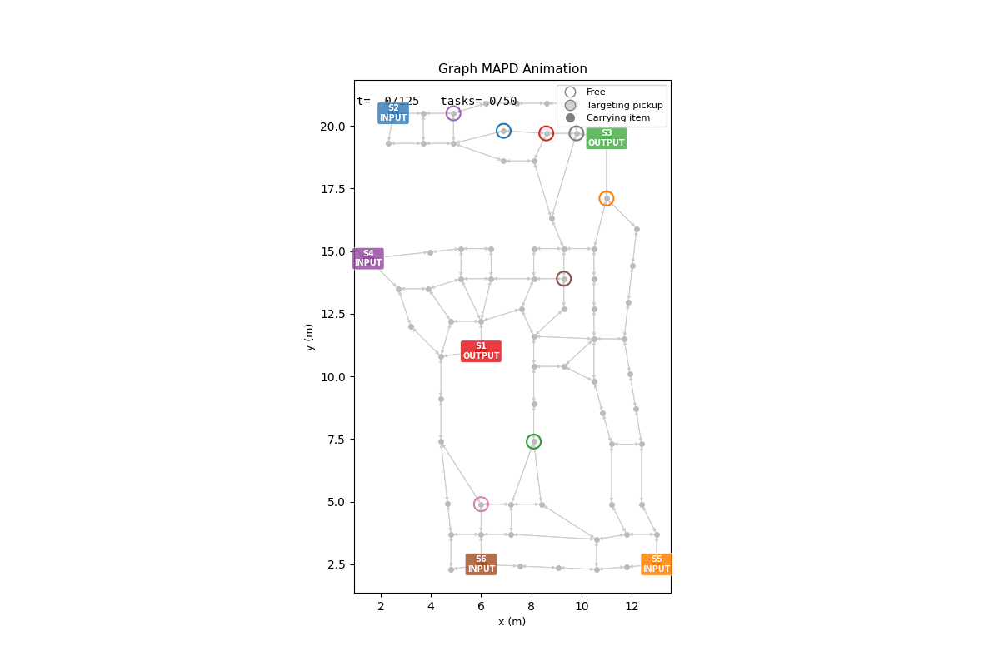

In [10]:
import sys
sys.path.append('..')

import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.animation as animation
from matplotlib.lines import Line2D
from matplotlib.animation import PillowWriter
from IPython.display import Image

graph      = graph_mapd.graph
NUM_AGENTS = graph_mapd.N
NUM_TASKS  = graph_mapd.instance.task_num
INTERP     = 5
FPS        = 20
GIF_PATH   = "../assets/demo_graph-mapd.gif"

# --- graph drawing helper ---------------------------------------------------
_PALETTE      = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628"]
station_ids   = list(graph.station_nodes.keys())
STATION_COLORS = {sid: _PALETTE[i % len(_PALETTE)] for i, sid in enumerate(station_ids)}
STATION_SET    = {n for nodes in graph.station_nodes.values() for n in nodes}

def draw_graph(ax):
    for from_idx, neighbors in graph.adjacency.items():
        x0, y0 = graph.node_positions[from_idx]
        for to_idx in neighbors:
            x1, y1 = graph.node_positions[to_idx]
            ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=1,
                arrowprops=dict(arrowstyle="-|>", color="#cccccc", lw=0.7, mutation_scale=6))
    for idx in range(graph.num_nodes):
        if idx in STATION_SET:
            continue
        x, y = graph.node_positions[idx]
        ax.plot(x, y, "o", color="#bbbbbb", markersize=4, zorder=2)
    for sid, node_indices in graph.station_nodes.items():
        color = STATION_COLORS[sid]
        for idx in node_indices:
            x, y = graph.node_positions[idx]
            ax.plot(x, y, "s", color=color, markersize=10, zorder=3,
                    markeredgecolor="white", markeredgewidth=0.5)
        xs   = [graph.node_positions[i][0] for i in node_indices]
        ys   = [graph.node_positions[i][1] for i in node_indices]
        desc = graph.station_descriptions.get(sid, "")
        ax.text(np.mean(xs), np.mean(ys), f"{sid}\n{desc}", fontsize=7,
                ha="center", va="center", fontweight="bold", color="white", zorder=5,
                bbox=dict(boxstyle="round,pad=0.25", facecolor=color,
                          alpha=0.85, edgecolor="white", linewidth=0.5))
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)", fontsize=9)
    ax.set_ylabel("y (m)", fontsize=9)

# --- animation data ---------------------------------------------------------
T          = len(solution)
positions  = np.array([graph.node_positions[i] for i in range(graph.num_nodes)])
goals_hist = graph_mapd.agent_goals_history

task_count_per_step = np.zeros(T, dtype=int)
for _, task in graph_mapd.completed_tasks:
    if task.timestep_finished is not None and task.timestep_finished < T:
        task_count_per_step[task.timestep_finished] += 1
cum_tasks    = np.cumsum(task_count_per_step)
AGENT_COLORS = [plt.cm.tab10(i % 10) for i in range(NUM_AGENTS)]

# --- build figure -----------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 8))
draw_graph(ax)
ax.set_title("Graph MAPD Animation", fontsize=11)
ax.legend(handles=[
    Line2D([0], [0], marker="o", color="w", markerfacecolor="white",
           markeredgecolor="grey", markersize=9, label="Free"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=(0.5, 0.5, 0.5, 0.35),
           markeredgecolor="grey", markersize=9, label="Targeting pickup"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="grey",
           markersize=9, label="Carrying item"),
], loc="upper right", fontsize=8)

goal_line_arts = [ax.plot([], [], "--", lw=0.8, alpha=0.6, zorder=6)[0] for _ in range(NUM_AGENTS)]
agent_scat = ax.scatter([], [], s=150, linewidths=1.5, zorder=7)
hud_text   = ax.text(0.01, 0.97, "", transform=ax.transAxes,
                     fontsize=10, va="top", fontfamily="monospace")
total_frames = (T - 1) * INTERP

def animate(frame):
    t     = min(frame // INTERP, T - 2)
    alpha = (frame % INTERP) / INTERP
    xs, ys, face_cols, edge_cols = [], [], [], []
    for aid in range(NUM_AGENTS):
        p0 = positions[solution[t][aid]]
        p1 = positions[solution[t + 1][aid]]
        xs.append(p0[0] + (p1[0] - p0[0]) * alpha)
        ys.append(p0[1] + (p1[1] - p0[1]) * alpha)
        goal_node, status = goals_hist[t][aid]
        r, g, b, _        = AGENT_COLORS[aid]
        edge_cols.append((r, g, b, 1.0))
        if status == "A":
            face_cols.append((r, g, b, 1.0))
        elif status == "T":
            face_cols.append((r, g, b, 0.35))
        else:
            face_cols.append((1.0, 1.0, 1.0, 0.0))
        if status != "F":
            gx, gy = positions[goal_node]
            goal_line_arts[aid].set_data([xs[-1], gx], [ys[-1], gy])
            goal_line_arts[aid].set_color((r, g, b))
        else:
            goal_line_arts[aid].set_data([], [])
    agent_scat.set_offsets(np.column_stack([xs, ys]))
    agent_scat.set_facecolor(face_cols)
    agent_scat.set_edgecolor(edge_cols)
    hud_text.set_text(f"t={t:3d}/{T-1}   tasks={cum_tasks[t]:2d}/{NUM_TASKS}")
    return [agent_scat, hud_text, *goal_line_arts]

anim = animation.FuncAnimation(fig, animate, frames=total_frames, interval=1000 // FPS, blit=True)
anim.save(GIF_PATH, writer=PillowWriter(fps=FPS))
plt.close(fig)
print(f"Animation saved â†’ {GIF_PATH}")
Image(filename=GIF_PATH)

## Summary

This notebook demonstrated **PIBT-based GRAPH-MAPD on directed LIF graphs**:

1. Loaded a directed graph and transport matrix from JSON
2. Solved with the PIBT algorithm â€” agents pick up and deliver items dynamically
3. Visualized the fleet as an animated GIF

**Key parameters:**

| Parameter | Description |
|-----------|-------------|
| `lif_file` | Path to the LIF JSON layout (nodes, directed edges, stations with coordinates) |
| `transport_matrix_file` | Station-to-station flow weights; determines task distribution |
| `num_agents` | Fleet size |
| `task_num` | Total tasks before the simulation stops |
| `task_mode` | `"global"` â€” shared FIFO queue, first free agent takes next task; `"per_agent"` â€” pre-assigned round-robin queues |
| `seed` | Random seed for reproducibility |

**Stats explanation:**
- **Makespan**: time from start until the last agent finishes its last task
- **Flowtime**: sum of all individual agent completion times (load balance metric)
- **Waittime**: total time agents spent blocked (not moving)
- **Congestion rate**: wait / move â€” higher means more traffic bottlenecks
- **Throughput**: completed tasks per second of makespan
